In [45]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sns.set_theme(style="whitegrid")

In [46]:
apps_raw = pd.read_csv("data/googleplaystore.csv")
reviews_raw = pd.read_csv("data/googleplaystore_user_reviews.csv")
print(apps_raw.shape, reviews_raw.shape)
apps_raw.head()

(10841, 13) (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [47]:
apps_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB


In [48]:
print(apps_raw.isna().sum())
print()
print(reviews_raw.isna().sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


In [49]:
print("Duplicate rows:", apps_raw.duplicated().sum())
print("Duplicate app names:", apps_raw["App"].duplicated().sum())

Duplicate rows: 483
Duplicate app names: 1181


In [50]:
print(apps_raw["Category"].value_counts().tail(3))
apps_raw[apps_raw["Category"] == "1.9"]

Category
PARENTING    60
BEAUTY       53
1.9           1
Name: count, dtype: int64


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [51]:
print(apps_raw["Installs"].unique())
print(apps_raw["Size"].value_counts().head(5))
print(apps_raw["Price"].unique()[:15])

<ArrowStringArray>
[       '10,000+',       '500,000+',     '5,000,000+',    '50,000,000+',
       '100,000+',        '50,000+',     '1,000,000+',    '10,000,000+',
         '5,000+',   '100,000,000+', '1,000,000,000+',         '1,000+',
   '500,000,000+',            '50+',           '100+',           '500+',
            '10+',             '1+',             '5+',             '0+',
              '0',           'Free']
Length: 22, dtype: str
Size
Varies with device    1695
11M                    198
12M                    196
14M                    194
13M                    191
Name: count, dtype: int64
<ArrowStringArray>
[    '0', '$4.99', '$3.99', '$6.99', '$1.49', '$2.99', '$7.99', '$5.99',
 '$3.49', '$1.99', '$9.99', '$7.49', '$0.99', '$9.00', '$5.49']
Length: 15, dtype: str


In [52]:
apps = apps_raw.copy()
apps = apps[apps["Category"] != "1.9"].copy()
print(apps.shape)   

(10840, 13)


In [53]:
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce")

apps["Installs"] = pd.to_numeric(
    apps["Installs"].str.replace(r"[+,]", "", regex=True), errors="coerce")

apps["Price"] = pd.to_numeric(
    apps["Price"].str.replace("$", "", regex=False), errors="coerce")

print(apps[["Reviews", "Installs", "Price"]].dtypes)
print(apps[["Reviews", "Installs", "Price"]].isna().sum())   # expect all 0

Reviews       int64
Installs      int64
Price       float64
dtype: object
Reviews     0
Installs    0
Price       0
dtype: int64


In [54]:
def size_to_mb(s):
    if s == "Varies with device":
        return np.nan
    if s.endswith("M"):
        return float(s[:-1])
    if s.endswith("k"):
        return float(s[:-1]) / 1024
    return np.nan

apps["Size_MB"] = apps["Size"].apply(size_to_mb)
print(apps["Size_MB"].describe())
print("Missing sizes:", apps["Size_MB"].isna().sum())   # expect ~1,695

count    9145.000000
mean       21.516165
std        22.589084
min         0.008301
25%         4.900000
50%        13.000000
75%        30.000000
max       100.000000
Name: Size_MB, dtype: float64
Missing sizes: 1695


In [55]:
apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], errors="coerce")
print(apps["Last Updated"].min(), apps["Last Updated"].max())

2010-05-21 00:00:00 2018-08-08 00:00:00


In [56]:
before = len(apps)
apps = (apps.sort_values("Reviews", ascending=False)
            .drop_duplicates(subset="App", keep="first")
            .reset_index(drop=True))
print(f"Removed {before - len(apps)} duplicates, {len(apps)} unique apps left")
# expect: Removed 1181, 9659 left

Removed 1181 duplicates, 9659 unique apps left


In [57]:

apps.loc[apps["Type"].isna() & (apps["Price"] == 0), "Type"] = "Free"

print(apps[["Type", "Rating", "Size_MB"]].isna().sum())

Type          0
Rating     1463
Size_MB    1228
dtype: int64


In [58]:
reviews = reviews_raw.dropna(subset=["Translated_Review"]).drop_duplicates().copy()
print(reviews.shape)

(29692, 5)


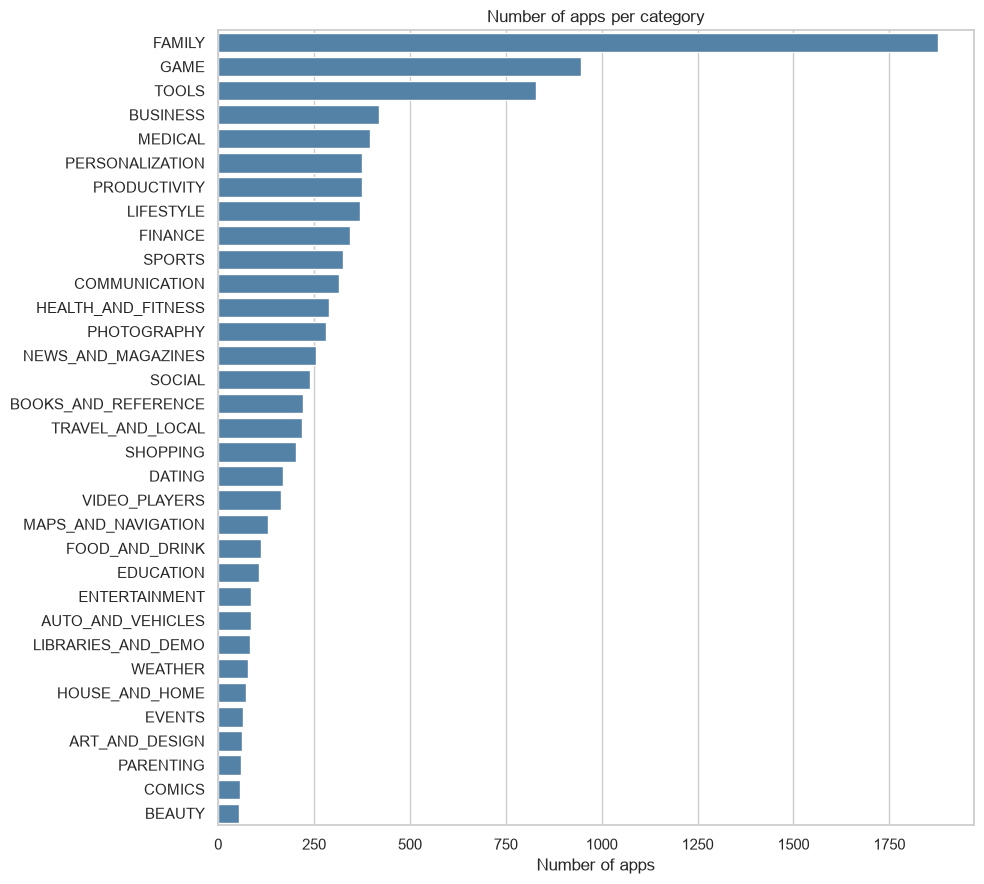

In [59]:
cat_counts = apps["Category"].value_counts()

plt.figure(figsize=(10, 9))
sns.barplot(x=cat_counts.values, y=cat_counts.index, color="steelblue")
plt.title("Number of apps per category")
plt.xlabel("Number of apps")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [60]:
share = (cat_counts / cat_counts.sum() * 100).round(1)
print(share.head(5))
print("Top 3 combined:", share.head(3).sum().round(1), "%")

Category
FAMILY      19.4
GAME         9.8
TOOLS        8.6
BUSINESS     4.3
MEDICAL      4.1
Name: count, dtype: float64
Top 3 combined: 37.8 %


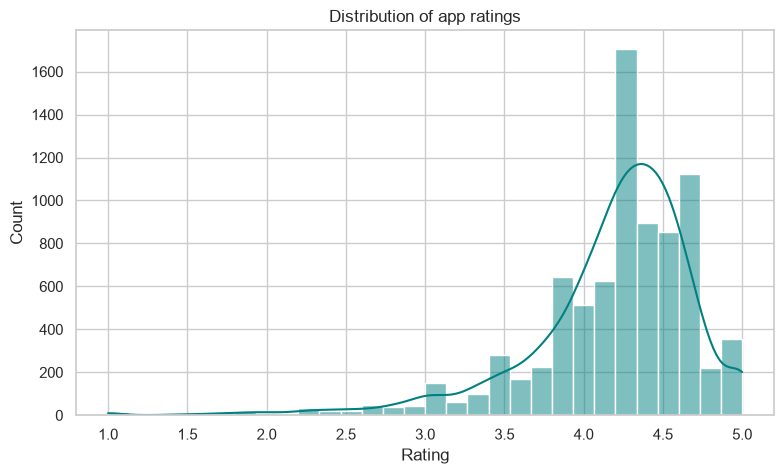

count    8196.00
mean        4.17
std         0.54
min         1.00
25%         4.00
50%         4.30
75%         4.50
max         5.00
Name: Rating, dtype: float64


In [61]:
rated = apps.dropna(subset=["Rating"])

plt.figure(figsize=(9, 5))
sns.histplot(rated["Rating"], bins=30, kde=True, color="teal")
plt.title("Distribution of app ratings")
plt.xlabel("Rating")
plt.show()

print(rated["Rating"].describe().round(2))

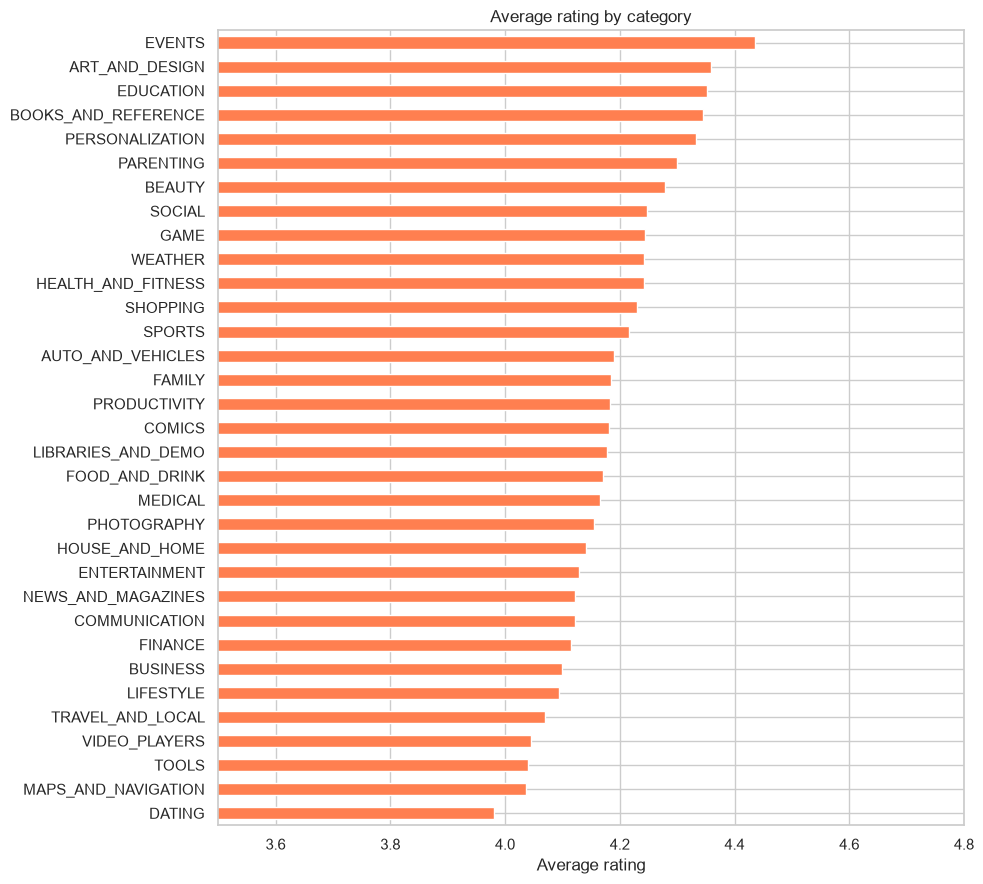

In [62]:
avg_cat = rated.groupby("Category")["Rating"].mean().sort_values()

plt.figure(figsize=(10, 9))
avg_cat.plot.barh(color="coral")
plt.title("Average rating by category")
plt.xlabel("Average rating")
plt.xlim(3.5, 4.8)
plt.ylabel("")
plt.tight_layout()
plt.show()

In [63]:
print("Highest:")
print(avg_cat.tail(3).round(2))
print()
print("Lowest:")
print(avg_cat.head(3).round(2))

Highest:
Category
EDUCATION         4.35
ART_AND_DESIGN    4.36
EVENTS            4.44
Name: Rating, dtype: float64

Lowest:
Category
DATING                 3.98
MAPS_AND_NAVIGATION    4.04
TOOLS                  4.04
Name: Rating, dtype: float64


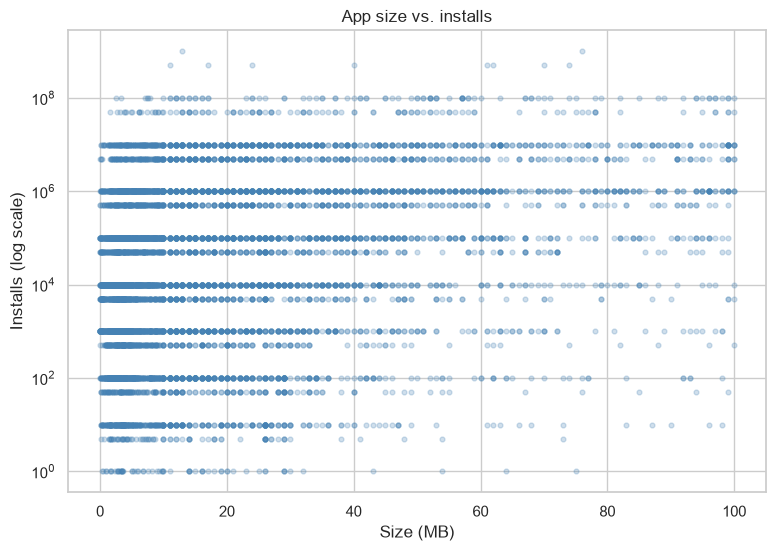

In [64]:
sz = apps.dropna(subset=["Size_MB"]).query("Installs > 0")

plt.figure(figsize=(9, 6))
plt.scatter(sz["Size_MB"], sz["Installs"], alpha=0.25, s=12, color="steelblue")
plt.yscale("log")
plt.xlabel("Size (MB)")
plt.ylabel("Installs (log scale)")
plt.title("App size vs. installs")
plt.show()

In [65]:
pearson = sz["Size_MB"].corr(np.log10(sz["Installs"]))
spearman = sz["Size_MB"].corr(sz["Installs"], method="spearman")
print("Pearson (size vs log installs):", round(pearson, 3))
print("Spearman:", round(spearman, 3))

Pearson (size vs log installs): 0.299
Spearman: 0.31


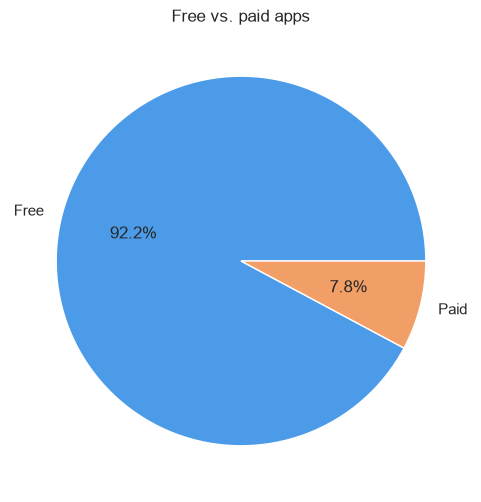

Type
Free    8905
Paid     754
Name: count, dtype: int64


In [66]:
type_counts = apps["Type"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", colors=["#4c9be8", "#f29f67"])
plt.title("Free vs. paid apps")
plt.show()

print(type_counts)

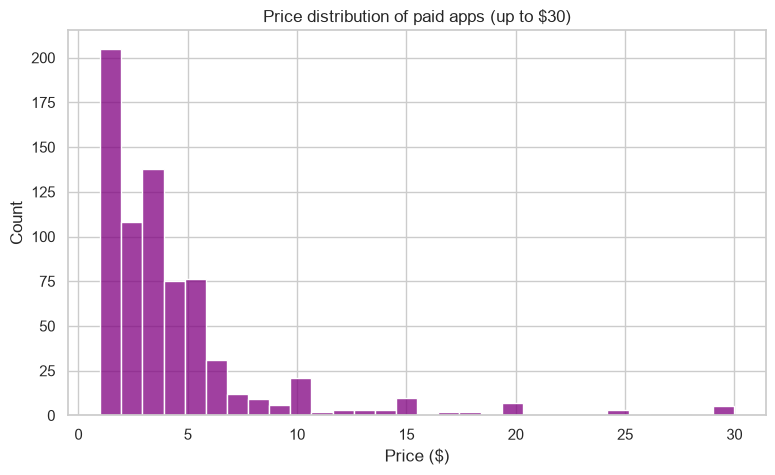

count    754.00
mean      14.06
std       58.82
min        0.99
25%        1.49
50%        2.99
75%        4.99
max      400.00
Name: Price, dtype: float64
Paid apps above $30: 29


In [67]:
paid = apps[(apps["Type"] == "Paid") & (apps["Price"] > 0)].copy()

plt.figure(figsize=(9, 5))
sns.histplot(paid[paid["Price"] <= 30]["Price"], bins=30, color="purple")
plt.title("Price distribution of paid apps (up to $30)")
plt.xlabel("Price ($)")
plt.show()

print(paid["Price"].describe().round(2))
print("Paid apps above $30:", (paid["Price"] > 30).sum())

In [68]:
print(apps.groupby("Type")["Installs"].median())

Type
Free    100000.0
Paid      1000.0
Name: Installs, dtype: float64


In [ ]:
paid["Est_Revenue"] = paid["Price"] * paid["Installs"]
rev_cat = paid.groupby("Category")["Est_Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
rev_cat.head(10).sort_values().plot.barh(color="seagreen")
plt.title("Estimated revenue by category (Price x Installs, top 10)")
plt.xlabel("Estimated revenue (USD)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(rev_cat.head(10).round(0))

In [ ]:
print(paid.nlargest(5, "Est_Revenue")[["App", "Category", "Price", "Installs", "Est_Revenue"]])

In [ ]:
sia = SentimentIntensityAnalyzer()
reviews["compound"] = reviews["Translated_Review"].astype(str).apply(lambda t: sia.polarity_scores(t)["compound"])
reviews[["Translated_Review", "compound"]].head()

In [ ]:
reviews["VADER_Sentiment"] = pd.cut(
    reviews["compound"],
    bins=[-1.01, -0.05, 0.05, 1.01],
    labels=["Negative", "Neutral", "Positive"]
)
print(reviews["VADER_Sentiment"].value_counts())
print()
print(reviews["VADER_Sentiment"].value_counts(normalize=True).mul(100).round(1))

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=reviews, x="VADER_Sentiment",
    order=["Positive", "Neutral", "Negative"],
    hue="VADER_Sentiment", palette=["#e53935", "#9e9e9e", "#4caf50"],
    legend=False
)
plt.title("Review sentiment (VADER)")
plt.xlabel("")
plt.ylabel("Number of reviews")
plt.show()

In [ ]:
print(pd.crosstab(reviews["Sentiment"], reviews["VADER_Sentiment"], normalize="index").round(2))

In [ ]:
cat_map = apps[["App", "Category"]]
rv = reviews.merge(cat_map, on="App", how="inner")
print("Reviews matched to a category:", len(rv))
print("Apps with reviews:", rv["App"].nunique())

In [ ]:
sent_cat = rv.groupby("Category").agg(
    n_reviews=("compound", "size"),
    avg_compound=("compound", "mean"),
    pct_positive=("VADER_Sentiment", lambda s: (s == "Positive").mean() * 100),
    pct_negative=("VADER_Sentiment", lambda s: (s == "Negative").mean() * 100)
)
sent_cat = sent_cat[sent_cat["n_reviews"] >= 100].sort_values("avg_compound")
sent_cat.round(2)

In [ ]:
plt.figure(figsize=(10, 8))
sent_cat["avg_compound"].plot.barh(color="slateblue")
plt.title("Average VADER sentiment by category (at least 100 reviews)")
plt.xlabel("Average compound score")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
print("Most positive:")
print(sent_cat["avg_compound"].tail(3).round(2))
print()
print("Least positive:")
print(sent_cat["avg_compound"].head(3).round(2))

In [ ]:
fig1 = px.scatter(
    sz, x="Size_MB", y="Installs", color="Category", log_y=True,
    hover_name="App", hover_data=["Rating", "Price"], opacity=0.6,
    title="App size vs. installs"
)
fig1.update_layout(height=600)
fig1.show()

In [ ]:
sent_plot = sent_cat.reset_index().sort_values("pct_positive")

fig2 = px.bar(
    sent_plot, x="pct_positive", y="Category", orientation="h",
    color="avg_compound", color_continuous_scale="RdYlGn",
    hover_data=["n_reviews", "pct_negative"],
    title="Percentage of positive reviews by category"
)
fig2.update_layout(height=700, xaxis_title="Positive reviews (%)", yaxis_title="")
fig2.show()

In [ ]:
rev_plot = rev_cat.head(10).reset_index()
rev_plot.columns = ["Category", "Est_Revenue"]

fig3 = px.bar(
    rev_plot.sort_values("Est_Revenue"), x="Est_Revenue", y="Category", orientation="h",
    title="Estimated revenue by category (top 10)", color="Est_Revenue",
    color_continuous_scale="Greens"
)
fig3.update_layout(height=500, xaxis_title="Estimated revenue (USD)", yaxis_title="")
fig3.show()

In [ ]:
cat_summary = apps.groupby("Category").agg(
    avg_rating=("Rating", "mean"),
    n_apps=("App", "size"),
    total_installs=("Installs", "sum")
).reset_index()

fig4 = px.scatter(
    cat_summary, x="n_apps", y="avg_rating", size="total_installs",
    hover_name="Category", title="Competition vs. quality by category"
)
fig4.update_layout(height=600, xaxis_title="Number of apps", yaxis_title="Average rating")
fig4.show()

In [ ]:
fig2.write_html("screenshots/sentiment_by_category.html")

In [ ]:
print("Most saturated:")
print(share.head(3))
print()
print("Free share (%):", round(type_counts["Free"] / type_counts.sum() * 100, 1))
print("Median paid price ($):", paid["Price"].median())
print()
print("Top revenue categories:")
print(rev_cat.head(3).round(0))
print()
print("Size vs installs Spearman:", round(spearman, 3))
print()
print("Most positive:")
print(sent_cat["pct_positive"].sort_values().tail(3).round(1))
print("Least positive:")
print(sent_cat["pct_positive"].sort_values().head(3).round(1))

In [ ]:
print(paid.nlargest(8, "Est_Revenue")[["App", "Category", "Price", "Installs", "Est_Revenue"]])

In [ ]:
paid_norm = paid[paid["Price"] <= 30]
rev_norm = paid_norm.groupby("Category")["Est_Revenue"].sum().sort_values(ascending=False)
print(rev_norm.head(5).round(0))

In [ ]:
rev_plot2 = rev_norm.head(10).reset_index()
rev_plot2.columns = ["Category", "Est_Revenue"]

fig3b = px.bar(
    rev_plot2.sort_values("Est_Revenue"), x="Est_Revenue", y="Category", orientation="h",
    title="Estimated revenue by category (apps priced up to $30, top 10)",
    color="Est_Revenue", color_continuous_scale="Greens"
)
fig3b.update_layout(height=500, xaxis_title="Estimated revenue (USD)", yaxis_title="")
fig3b.show()

## 10. Conclusion: 3 data-driven insights for a developer

**1. Avoid the three crowded categories unless the app is clearly differentiated.**
FAMILY (19.4%), GAME (9.8%) and TOOLS (8.6%) together hold about 38% of all apps. Ratings are similar across categories (mostly between 4.0 and 4.4), so quality alone will not make a new app stand out in a crowded space. Mid-sized categories with 200 to 400 apps and above-average ratings offer a better entry point.

**2. Build for free with in-app monetisation; price a paid app low.**
92.2% of apps are free and the median paid price is only $2.99. Estimated paid revenue (price x installs, a rough lower bound) is concentrated in FAMILY (about $105.7M) and GAME (about $40.7M) once extreme novelty apps priced above $30, such as "I am rich" at $399.99, are excluded. Those outliers alone made LIFESTYLE and FINANCE look lucrative. Even in FAMILY, a single title (Minecraft) accounts for most of the revenue, so paid-app income is highly concentrated in a few hits rather than spread across the category.

**3. Use review sentiment to find unmet user needs.**
HEALTH_AND_FITNESS (78.5% positive), EVENTS (80.1%) and AUTO_AND_VEHICLES (82.3%) have the happiest users, while SOCIAL (55.1%), VIDEO_PLAYERS (56.7%) and NEWS_AND_MAGAZINES (57.6%) have the least positive reviews. Low sentiment suggests users are dissatisfied with existing apps, so a well-built app in these categories has room to win. App size has only a weak positive relationship with installs (Spearman = 0.31), so size should not drive design decisions.


In [1]:
%%writefile README.md
# Task 4 · Unveiling the Android App Market (Google Play Store Analysis)

**Track:** Data Analytics · **Internship:** OIBSIP

## Objective
Perform a data analysis of the Google Play Store ecosystem: clean messy real-world data, explore app categories, analyse ratings and pricing, estimate revenue, and run sentiment analysis on user reviews, in order to give data-driven advice to a developer planning to launch a new app.

## Tech Stack
Python, pandas, numpy, matplotlib, seaborn, plotly, VADER (vaderSentiment), Jupyter Notebook

## Dataset
Kaggle: [Google Play Store Apps](https://www.kaggle.com/lava18/google-play-store-apps) by Lavanya Gupta

- `googleplaystore.csv`: 10,841 rows, 13 columns (app details)
- `googleplaystore_user_reviews.csv`: 64,295 rows, 5 columns (user reviews)

The CSV files are not included in this repository. Download them from Kaggle and place them in the `data/` folder.

## Project Structure
```
DataAnalytics-Task4-PlayStoreAnalysis/
├── Task4_Google_Play_Store_Analysis.ipynb
├── README.md
├── requirements.txt
├── data/            (place the two CSV files here)
└── screenshots/     (charts from the analysis)
```

## How to Run
```bash
pip install -r requirements.txt
jupyter notebook Task4_Google_Play_Store_Analysis.ipynb
```
Then run all cells from top to bottom (Kernel → Restart & Run All).

## What the Notebook Covers
- [x] Load the apps and reviews datasets separately
- [x] Data cleaning: fixed data types (Installs, Price, Size, Reviews, Last Updated), handled nulls, removed duplicates and one corrupted row
- [x] Category analysis: app distribution and saturation
- [x] Ratings analysis: distribution and average rating by category
- [x] Size vs. installs: scatter plot and correlation
- [x] Pricing analysis: free vs. paid, price distribution, estimated revenue by category
- [x] Sentiment analysis of user reviews with VADER (positive / neutral / negative)
- [x] Sentiment by category
- [x] Interactive visualisations with Plotly
- [x] Conclusion: 3 data-driven insights for a developer

## Data Cleaning Summary
- Removed 1 corrupted row (columns shifted, Category = "1.9")
- Converted `Installs` ("10,000+") and `Price` ("$4.99") to numbers
- Converted `Size` ("19M", "201k") to megabytes; "Varies with device" left as missing
- Converted `Reviews` to numeric and `Last Updated` to datetime
- Removed duplicate apps by keeping the entry with the most reviews
- Left missing `Rating` and `Size` values empty instead of filling them, to avoid inventing data
- Dropped reviews with no text before sentiment scoring

## Key Findings
- **Category saturation:** FAMILY (19.4%), GAME (9.8%) and TOOLS (8.6%) are the most crowded categories.
- **Pricing:** 92.2% of apps are free; the median price of a paid app is $2.99.
- **Size vs. installs:** weak positive relationship (Spearman = 0.31).
- **Revenue (price x installs, apps priced up to $30):** highest in FAMILY (about $105.7M) and GAME (about $40.7M).
- **Sentiment:** most positive categories are AUTO_AND_VEHICLES (82.3% positive), EVENTS (80.1%) and HEALTH_AND_FITNESS (78.5%); least positive are SOCIAL (55.1%), VIDEO_PLAYERS (56.7%) and NEWS_AND_MAGAZINES (57.6%).

## Conclusion: 3 Insights for a Developer
1. **Avoid the crowded categories unless the app is clearly differentiated.** FAMILY, GAME and TOOLS hold about 38% of all apps, and ratings are similar across categories, so quality alone will not make a new app stand out. Mid-sized categories offer a better entry point.
2. **Build for free with in-app monetisation; price a paid app low.** With 92.2% of apps free and a median paid price of $2.99, paid apps are a small, price-sensitive niche. Paid revenue is concentrated in a few hit titles (for example Minecraft in FAMILY).
3. **Use review sentiment to find unmet user needs.** Categories with low positive sentiment (SOCIAL, VIDEO_PLAYERS, NEWS_AND_MAGAZINES) suggest users are dissatisfied with current apps, which leaves room for a better product. App size has only a weak link to installs, so it should not drive design decisions.

## Limitations
- Revenue is estimated as Price x Installs. Installs are reported as floor values (for example "10,000+"), and store fees and refunds are ignored, so this is a rough lower bound.
- Apps priced above $30 were excluded from the revenue analysis because novelty apps (for example "I am rich", $399.99) distort the totals.
- Only a subset of apps have user reviews, so sentiment by category covers fewer categories than the other analyses. Categories with fewer than 100 reviews were left out.
- The data was scraped in 2018, so current market conditions may differ.

## Screenshots

### Apps per category
![Category distribution](screenshots/category_distribution.png)

### Ratings distribution
![Ratings distribution](screenshots/ratings_distribution.png)

### Size vs. installs
![Size vs installs](screenshots/size_vs_installs.png)

### Estimated revenue by category
![Revenue by category](screenshots/revenue_by_category.png)

### Review sentiment (VADER)
![Sentiment distribution](screenshots/sentiment_distribution.png)

### Sentiment by category
![Sentiment by category](screenshots/sentiment_by_category.png)

Writing README.md


In [2]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
plotly
vaderSentiment
jupyter

Writing requirements.txt


In [3]:
import os
print(os.getcwd())
print(os.listdir("."))

C:\Users\N6N0C\OIBSIP\DataAnalytics-Task4-PlayStoreAnalysis
['.ipynb_checkpoints', 'anaconda_projects', 'data', 'README.md', 'requirements.txt', 'screenshots', 'Task4_Google_Play_Store_Analysis.ipynb']
